### Experiment Notes

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Training / Load / Data

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [1]:
import os
import pathlib
import requests
import tqdm
import numpy as np
import gzip
import gc
import matplotlib.pyplot as plt
%matplotlib inline


In [2]:
train_images_filename = 'data/train-images-idx3-ubyte.gz'
train_labels_filename = 'data/train-labels-idx1-ubyte.gz'
test_images_filename  = 'data/t10k-images-idx3-ubyte.gz'
test_labels_filename  = 'data/t10k-labels-idx1-ubyte.gz'

def read_mnist_image_set(images_filename):
    with gzip.GzipFile(images_filename, 'rb') as gz:
        magic = int.from_bytes(gz.read(4), 'big')
        assert magic == 2051, f'Not an MNIST image set'

        num_images = int.from_bytes(gz.read(4), 'big')
        rows = int.from_bytes(gz.read(4), 'big')
        cols = int.from_bytes(gz.read(4), 'big')

        data = np.frombuffer(gz.read(num_images * rows * cols), dtype=np.uint8)
        data = np.reshape(data, (num_images, rows * cols))
        return data

def read_mnist_label_set(labels_filename):
    with gzip.GzipFile(labels_filename, 'rb') as gz:
        magic = int.from_bytes(gz.read(4), 'big')
        assert magic == 2049, f'Not an MNIST label set'

        num_labels = int.from_bytes(gz.read(4), 'big')
        labels = np.frombuffer(gz.read(num_labels), dtype=np.uint8)
        return labels

print('\nLoading train set ...')
train_data   = read_mnist_image_set(train_images_filename) / np.float32(255)
train_labels = read_mnist_label_set(train_labels_filename)
print(f'train_data:   [{str(train_data.dtype)  }] {train_data.shape}')
print(f'train_labels: [{str(train_labels.dtype)}] {train_labels.shape}')

print('\nLoading test set ...')
test_data   = read_mnist_image_set(test_images_filename) / np.float32(255)
test_labels = read_mnist_label_set(test_labels_filename)
print(f'test_data:   [{str(test_data.dtype)  }] {test_data.shape}')
print(f'test_labels: [{str(test_labels.dtype)}] {test_labels.shape}')



Loading train set ...
train_data:   [float32] (60000, 784)
train_labels: [uint8] (60000,)

Loading test set ...
test_data:   [float32] (10000, 784)
test_labels: [uint8] (10000,)


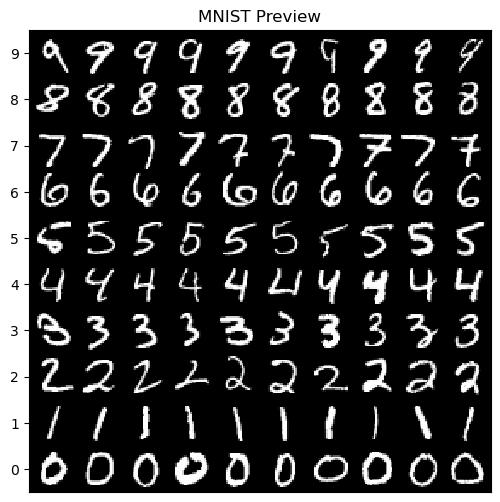

In [3]:
# Preview dataset

_ = plt.figure(figsize=(6, 6))
_ = plt.title('MNIST Preview')
for label in range(10):
    for img_index, img_data in enumerate(test_data[test_labels == label][:10]):
        _ = plt.imshow(img_data.reshape(28, 28), 'gray', vmin=0, vmax=1,
            interpolation='nearest', extent=(img_index, img_index + 1, label, label + 1))
_ = plt.xticks([])
_ = plt.yticks(np.arange(10) + 0.5, list(map(str, range(10))))
_ = plt.xlim(0, 10)
_ = plt.ylim(0, 10)

### Experiment Notes

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [4]:
class Network():
    ''' 简单的序列神经网络模型 '''
    def __init__(self):
        self.layers = []

    def add(self, layer):
        self.layers.append(layer)

    def forward(self, x):
        # Note on Compute. Refer to the archived source for the detailed original comment.
        for i in range(len(self.layers)):
            x = self.layers[i].forward(x)
        return x

    def backward(self, delta):
        # Note on Compute. Refer to the archived source for the detailed original comment.
        for i in reversed(range(len(self.layers))): # 逆向遍历
            delta = self.layers[i].backward(delta)


### Gradient

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [6]:
class SGD():
    def __init__(self, learning_rate, weight_decay, momentum=0.9):
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        self.momentum = momentum

    # Note on Parameters. Refer to the archived source for the detailed original comment.
    def step(self, model: Network):
        layers = model.layers
        for layer in layers:
            if layer.trainable:

                if not hasattr(layer, 'v_W'):
                    layer.v_W = np.zeros_like(layer.W)
                    layer.v_b = np.zeros_like(layer.b)
                # Note on Compute, Gradient. Refer to the archived source for the detailed original comment.
                grad_W = layer.grad_W + self.weight_decay * layer.W
                grad_b = layer.grad_b
                # 动量更新
                layer.v_W = self.momentum * layer.v_W - self.learning_rate * grad_W
                layer.v_b = self.momentum * layer.v_b - self.learning_rate * grad_b
                layer.W += layer.v_W
                layer.b += layer.v_b

### Output / Input / Weights

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

2.2 `FCLayer`
$$
\mathbf{u} = \mathbf{W} \mathbf{x} + \mathbf{b}
$$


In [7]:
class FCLayer():
    ''' 全连接层 '''
    def __init__(self, num_input, num_output, act_function='relu', trainable=True):
        '''
    对输入进行线性变换: y = Wx + b
    参数简介:
            num_input: 输入大小
            num_output: 输出大小
            act_function: 激活函数类型(无需修改)
            trainable: 是否具有可训练的参数
        '''
        self.num_input = num_input
        self.num_output = num_output
        self.trainable = trainable
        self.act_function = act_function
        assert act_function in ['relu', 'sigmoid']

        self._xavier_init()

        self.grad_W = np.zeros((num_input, num_output))
        self.grad_b = np.zeros((1, num_output))

        # Note on Save. Refer to the archived source for the detailed original comment.
        self.input = None      # 输入 x
        self.u = None          # 线性输出 Wx + b


    def forward(self, input):

        ############################################################################
        # TODO
        # Note on Results, Input, Compute. Refer to the archived source for the detailed original comment.
    
        self.input = input                     # 保存输入，用于反向传播
        self.u = input @ self.W + self.b       # 线性部分 (batch_size, num_output)

        return self.u
        ############################################################################


    def backward(self, delta):
        # Note on Input, Compute, Gradient. Refer to the archived source for the detailed original comment.
        ############################################################################
        # TODO
        # Note on Compute, Gradient. Refer to the archived source for the detailed original comment.

        # Note on Parameters, Compute, Gradient. Refer to the archived source for the detailed original comment.
        batch_size = self.input.shape[0]
        self.grad_W = (self.input.T @ delta)/ batch_size 
        self.grad_b = np.mean(delta, axis=0, keepdims=True)

        delta_prev = delta @ self.W.T 

        return delta_prev #误差信号向前一层反向传播
        ############################################################################


    def _xavier_init(self):
        # Note on Initialize. Refer to the archived source for the detailed original comment.
        raw_std = (2 / (self.num_input + self.num_output))**0.5
        if 'relu' == self.act_function:
            init_std = raw_std * (2**0.5)  # He 初始化（何恺明初始化），对于 ReLU 激活函数是最优解
        elif 'sigmoid' == self.act_function:
            init_std = raw_std     # Xavier 初始化， Sigmoid 激活的标准配置
        else:
            init_std = raw_std # * 4

        self.W = np.random.normal(0, init_std, (self.num_input, self.num_output))
        self.b = np.random.normal(0, init_std, (1, self.num_output))

### Experiment Notes

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

2.3 `SigmoidLayer`
$$
f(\mathbf{u}) = \frac{1}{1 + \exp(-\mathbf{u})}
$$


In [8]:
class SigmoidLayer():
    ''' Sigmoid激活层 '''
    def __init__(self):
        '''
        Sigmoid激活函数: f(x) = 1/(1+exp(-x))
        '''
        self.trainable = False
        self.y = None      # 保存激活输出

    def forward(self, input):

        ############################################################################
        # TODO
        # Note on Results, Input. Refer to the archived source for the detailed original comment.

        # Note on Output. Refer to the archived source for the detailed original comment.
        self.y = 1 / (1 + np.exp(-input))

        return self.y
        ############################################################################

    def backward(self, delta):

        ############################################################################
        # TODO
        # Note on Compute, Gradient. Refer to the archived source for the detailed original comment.
        d_act = self.y * (1 - self.y)             # sigmoid 导数：y(1-y)
        # Note on Gradient. Refer to the archived source for the detailed original comment.
        delta_prev = delta * d_act                 # 传回给线性层

        return delta_prev
        ############################################################################


### Experiment Notes

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

2.4 `ReLULayer`
$$
f(\mathbf{u}) = \max(\mathbf{0}, \mathbf{u})
$$


In [9]:
class ReLULayer():
    ''' ReLU激活层 '''
    def __init__(self):
        '''
        ReLU激活函数: relu(x) = max(x, 0)
        '''
        self.trainable = False # 没有可训练的参数
        self.y = None      # 保存激活输出

    def forward(self, input):

        ############################################################################
        # TODO
        # Note on Results, Input. Refer to the archived source for the detailed original comment.

        self.mask = (input > 0)
        self.y = np.maximum(0, input)

        return self.y
        ############################################################################


    def backward(self, delta):

        ############################################################################
        # TODO
        # Note on Compute, Gradient. Refer to the archived source for the detailed original comment.

        # Note on Compute, Gradient. Refer to the archived source for the detailed original comment.
        d_act = self.mask.astype(float)             # ReLU 导数：u>0 时为1，否则0
        
        # Note on Gradient. Refer to the archived source for the detailed original comment.
        delta_prev = delta * d_act

        return delta_prev
        ############################################################################


### Compute / Samples

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

2.5 `EuclideanLossLayer`
$$
\frac{1}{2} \sum_{n} \lVert \operatorname{logits}(n) - \operatorname{label}(n) \rVert _2^2
$$


In [10]:
class EuclideanLossLayer():
    ''' 欧式距离损失层 '''
    def __init__(self):
        self.acc = 0.
        self.loss = 0.
        self.logit = None   # 保存前向输入，供反向传播使用
        self.gt = None

    def forward(self, logit, gt):
        '''
         输入: (minibatch)
          - logit: 最后一个全连接层的输出结果, 尺寸(batch_size, 10)
          - gt: 真实标签, 尺寸(batch_size, 10)
        '''

        ############################################################################
        # TODO
        # Note on Training, Accuracy, Save, Compute. Refer to the archived source for the detailed original comment.
        # 只需要返回self.loss

        self.logit = logit
        self.gt = gt
        batch_size = logit.shape[0]

        diff = logit - gt
        self.loss = np.mean(0.5 * (diff ** 2))

        # Note on Accuracy, Classification, Compute. Refer to the archived source for the detailed original comment.
        pred = np.argmax(logit, axis=1)
        true = np.argmax(gt, axis=1)
        self.acc = np.mean(pred == true)
        ############################################################################

        return self.loss

    def backward(self):

        ############################################################################
        # TODO
        # Note on Compute, Gradient. Refer to the archived source for the detailed original comment.

        delta = self.logit - self.gt

        return delta
        ############################################################################


### Training / Parameters / Output

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

2.6 `SoftmaxCrossEntropyLossLayer`
$$
P(t_k=1\vert\mathbf{x}) = \frac{\exp(x_k)}{\sum_{j=1}^{K}\exp(x_j)}
$$
$$
E = -\ln p(t^{(1)}, \dots, t^{(N)}) = \sum_{n=1}^N E^{(n)}
$$
$$
E^{(n)} = -\sum_{k=1}^K t_k^{(n)} \ln h_k^{(n)}
$$


In [11]:
class SoftmaxCrossEntropyLossLayer():
    ''' Softmax交叉熵损失层 '''
    def __init__(self):
        self.acc = 0.
        self.loss = np.zeros(1, dtype='f')
        self.logit = None   # 保存前向输入，供反向传播使用
        self.gt = None

    def forward(self, logit, gt):
        '''
          输入: (minibatch)
          - logit: 最后一个全连接层的输出结果, 尺寸(batch_size, 10)
          - gt: 真实标签, 尺寸(batch_size, 10)
        '''

        ############################################################################
        # TODO
        # Note on Training, Accuracy, Save, Compute. Refer to the archived source for the detailed original comment.
        # 只需要返回self.loss

        self.gt = gt

        # 数值稳定的 softmax = 减掉最大值
        logit_shift = logit - np.max(logit, axis=1, keepdims=True)
        exp_logit = np.exp(logit_shift)
        self.probs = exp_logit / np.sum(exp_logit, axis=1, keepdims=True)

        # Note on Compute. Refer to the archived source for the detailed original comment.
        # -np.sum(gt * log(probs), axis=1)
        probs_clipped = np.clip(self.probs, EPS, 1 - EPS)
        loss_per_sample = -np.sum(self.gt * np.log(probs_clipped), axis=1)
        self.loss = np.mean(loss_per_sample)

        # Note on Accuracy, Classification, Compute. Refer to the archived source for the detailed original comment.
        pred = np.argmax(logit, axis=1)
        true = np.argmax(gt, axis=1)
        self.acc = np.mean(pred == true)
        ############################################################################

        return self.loss


    def backward(self):

        ############################################################################
        # TODO
        # Note on Gradient. Refer to the archived source for the detailed original comment.
        delta = self.probs - self.gt

        return delta
        ############################################################################


### Training / Code

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [12]:
# Note on Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.

batch_size = 100
max_epoch = 8
init_std = 0.01

weight_decay = 0.001
learning_rate_SGD = 0.01 #降低学习率

# 为了防止分母为零，必要时可在分母加上一个极小项EPS
EPS = 1e-11

In [14]:
def train(model, criterion, optimizer):
    avg_train_losses, avg_train_accs = [], []
    avg_test_losses, avg_test_accs = [], []

    # Train
    for epoch in range(max_epoch):
        # Train one epoch
        batch_train_losses, batch_train_accs = [], []

        steps_per_epoch = np.ceil(len(train_data) / batch_size).astype(int)
        batch_split_indices = np.arange(batch_size, len(train_data), batch_size)
        train_data_batches = np.split(train_data, batch_split_indices)
        train_labels_batches = np.split(train_labels, batch_split_indices)

        progress_bar = tqdm.tqdm(range(steps_per_epoch), desc=f'Ep[{epoch}]')
        for step_index in progress_bar:
            # Get train data and label
            x = np.reshape(train_data_batches[step_index], (-1, 784))   # x.shape: [batch_size, 784]
            y_true = np.eye(10)[train_labels_batches[step_index]]       # y_true.shape (one-hot): [batch_size, 10]

            # Forward pass
            y_pred = model.forward(x)
            criterion.forward(y_pred, y_true)

            # Backward pass
            delta = criterion.backward()
            model.backward(delta)

            # Update weights
            optimizer.step(model)

            # Record loss and accuracy
            batch_train_losses.append(criterion.loss)
            batch_train_accs.append(criterion.acc)
            progress_bar.set_description(f'Ep[{epoch}] loss:{criterion.loss:.3f} acc:{criterion.acc:.3f}')

        # Test
        # Get test data and label
        x = np.reshape(test_data, (-1, 784)) # x.shape: [batch_size, 784]
        y_true = np.eye(10)[test_labels]     # y_true.shape (one-hot): [batch_size, 10]

        # Only forward pass
        y_pred = model.forward(x)
        criterion.forward(y_pred, y_true)

        # Record loss and accuracy
        test_loss = criterion.loss
        test_acc = criterion.acc

        avg_train_losses.append(np.mean(batch_train_losses))
        avg_train_accs.append(np.mean(batch_train_accs))
        avg_test_losses.append(np.mean(test_loss))
        avg_test_accs.append(np.mean(test_acc))
        print(f'  - Test loss:{avg_test_losses[-1]:.4f} acc:{avg_test_accs[-1]:.4f}')

    # plot loss & accuracy curve
    x_by_epoch = (np.arange(max_epoch) + 1) * steps_per_epoch
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 4))
    _ = a0.set_title('Losses')
    _ = a0.plot(x_by_epoch, avg_train_losses, marker='.', label='train')
    _ = a0.plot(x_by_epoch, avg_test_losses, marker='.', label='test')
    _ = a0.legend()
    _ = a1.set_title('Accuracies')
    _ = a1.plot(x_by_epoch, avg_train_accs, marker='.', label='train')
    _ = a1.plot(x_by_epoch, avg_test_accs, marker='.', label='test')
    _ = a1.legend()

    return model, avg_test_losses, avg_test_accs


Ep[0] loss:0.014 acc:0.910: 100%|██████████| 600/600 [00:01<00:00, 308.24it/s]


  - Test loss:0.0131 acc:0.9009


Ep[1] loss:0.011 acc:0.940: 100%|██████████| 600/600 [00:01<00:00, 302.47it/s]


  - Test loss:0.0106 acc:0.9146


Ep[2] loss:0.010 acc:0.950: 100%|██████████| 600/600 [00:02<00:00, 279.89it/s]


  - Test loss:0.0098 acc:0.9188


... (6 outputs left out)

Ep[6] loss:0.009 acc:0.960: 100%|██████████| 600/600 [00:02<00:00, 297.44it/s]


  - Test loss:0.0088 acc:0.9256


Ep[7] loss:0.009 acc:0.960: 100%|██████████| 600/600 [00:02<00:00, 294.90it/s]


  - Test loss:0.0086 acc:0.9262


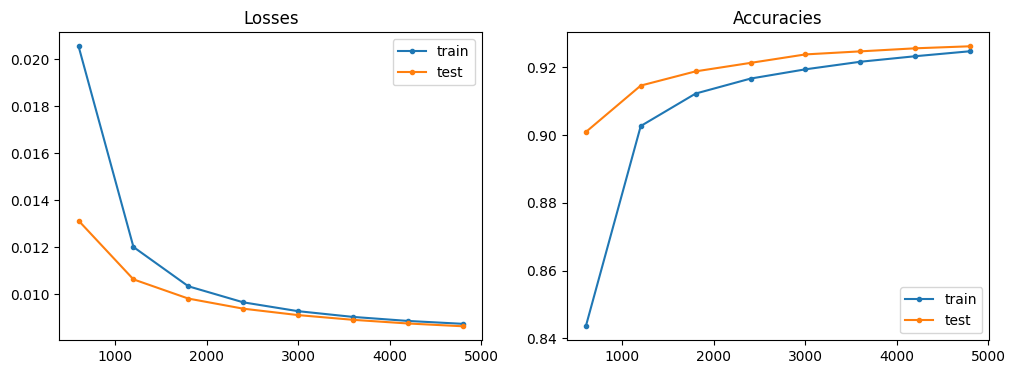

In [25]:
learning_rate_SGD = 0.05 #增大学习率

# Sigmoid激活，欧式距离损失
# 128是隐藏层单元数，可根据需要修改
mlp_sigmoid_euclidean = Network()
mlp_sigmoid_euclidean.add(FCLayer(784, 128, act_function='sigmoid'))
mlp_sigmoid_euclidean.add(SigmoidLayer())
mlp_sigmoid_euclidean.add(FCLayer(128, 10, act_function='sigmoid'))

criterion_euclidean = EuclideanLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_sigmoid_euclidean, avg_test_losses, avg_test_accs = train(mlp_sigmoid_euclidean, criterion_euclidean, sgd)


### Experiment / Results and Analysis / Results

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Ep[0] loss:0.011 acc:0.950: 100%|██████████| 600/600 [00:02<00:00, 286.37it/s]


  - Test loss:0.0109 acc:0.9193


Ep[1] loss:0.008 acc:0.980: 100%|██████████| 600/600 [00:02<00:00, 296.02it/s]


  - Test loss:0.0090 acc:0.9342


Ep[2] loss:0.007 acc:0.990: 100%|██████████| 600/600 [00:02<00:00, 289.66it/s]


  - Test loss:0.0081 acc:0.9420


... (6 outputs left out)

Ep[6] loss:0.006 acc:0.990: 100%|██████████| 600/600 [00:01<00:00, 303.58it/s]


  - Test loss:0.0066 acc:0.9557


Ep[7] loss:0.006 acc:0.990: 100%|██████████| 600/600 [00:01<00:00, 319.35it/s]


  - Test loss:0.0064 acc:0.9577


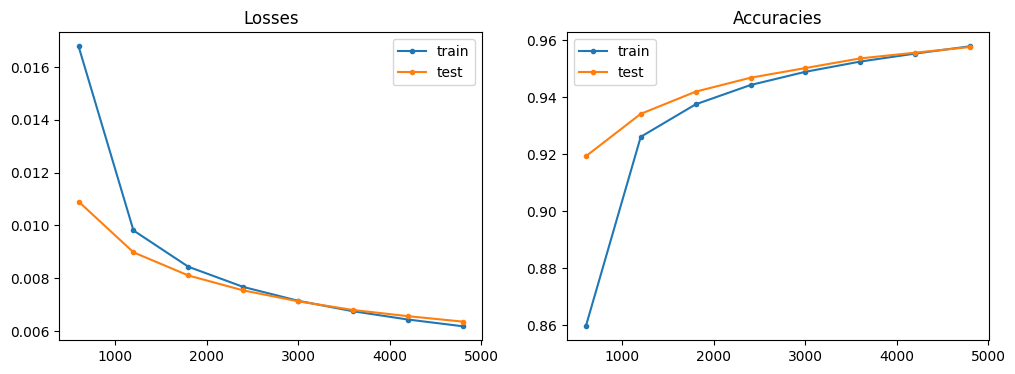

In [15]:
# ReLU激活，欧式距离损失
# 128是隐藏层单元数，可根据需要修改
mlp_relu_euclidean = Network()
mlp_relu_euclidean.add(FCLayer(784, 128, act_function='sigmoid'))
mlp_relu_euclidean.add(ReLULayer())
mlp_relu_euclidean.add(FCLayer(128, 10, act_function='sigmoid'))

criterion_euclidean = EuclideanLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_relu_euclidean, avg_test_losses, avg_test_accs = train(mlp_relu_euclidean, criterion_euclidean, sgd)


### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Ep[0] loss:0.503 acc:0.880: 100%|██████████| 600/600 [00:01<00:00, 307.67it/s]


  - Test loss:0.4383 acc:0.8891


Ep[1] loss:0.409 acc:0.920: 100%|██████████| 600/600 [00:01<00:00, 308.58it/s]


  - Test loss:0.3555 acc:0.9040


Ep[2] loss:0.375 acc:0.920: 100%|██████████| 600/600 [00:01<00:00, 309.46it/s]


  - Test loss:0.3249 acc:0.9110


... (6 outputs left out)

Ep[6] loss:0.321 acc:0.940: 100%|██████████| 600/600 [00:02<00:00, 293.56it/s]


  - Test loss:0.2807 acc:0.9222


Ep[7] loss:0.314 acc:0.940: 100%|██████████| 600/600 [00:01<00:00, 304.38it/s]


  - Test loss:0.2746 acc:0.9247


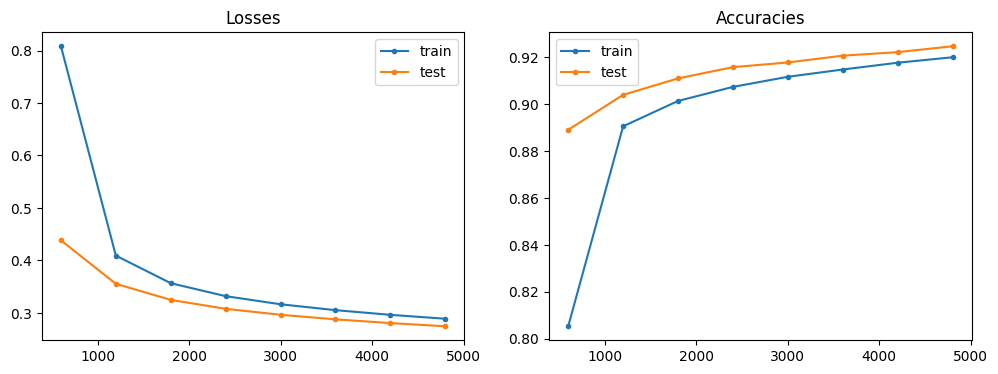

In [16]:
# Sigmoid激活，交叉熵损失
# 128是隐藏层单元数，可根据需要修改
mlp_sigmoid_ce = Network()
mlp_sigmoid_ce.add(FCLayer(784, 128))
mlp_sigmoid_ce.add(SigmoidLayer())
mlp_sigmoid_ce.add(FCLayer(128, 10))

criterion_ce = SoftmaxCrossEntropyLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_sigmoid_ce, avg_test_losses, avg_test_accs = train(mlp_sigmoid_ce, criterion_ce, sgd)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Ep[0] loss:0.294 acc:0.950: 100%|██████████| 600/600 [00:02<00:00, 274.39it/s]


  - Test loss:0.2628 acc:0.9237


Ep[1] loss:0.240 acc:0.980: 100%|██████████| 600/600 [00:02<00:00, 299.02it/s]


  - Test loss:0.2029 acc:0.9408


Ep[2] loss:0.215 acc:0.990: 100%|██████████| 600/600 [00:02<00:00, 285.32it/s]


  - Test loss:0.1695 acc:0.9504


... (6 outputs left out)

Ep[6] loss:0.175 acc:0.990: 100%|██████████| 600/600 [00:02<00:00, 291.41it/s]


  - Test loss:0.1200 acc:0.9665


Ep[7] loss:0.170 acc:0.990: 100%|██████████| 600/600 [00:02<00:00, 291.15it/s]


  - Test loss:0.1148 acc:0.9676


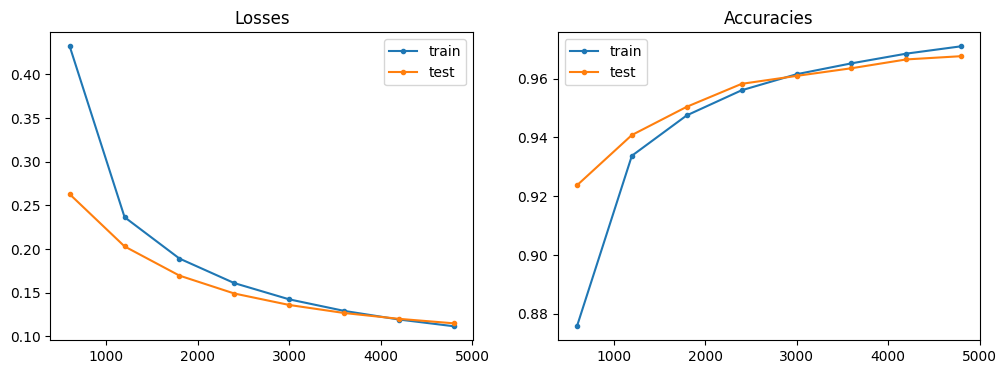

In [17]:
# ReLU激活，交叉熵损失
# 128是隐藏层单元数，可根据需要修改
mlp_relu_ce = Network()
mlp_relu_ce.add(FCLayer(784, 128))
mlp_relu_ce.add(ReLULayer())
mlp_relu_ce.add(FCLayer(128, 10))

criterion_ce = SoftmaxCrossEntropyLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_relu_ce, avg_test_losses, avg_test_accs = train(mlp_relu_ce, criterion_ce, sgd)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Model

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Ep[0] loss:0.292 acc:0.960: 100%|██████████| 600/600 [00:03<00:00, 169.68it/s]


  - Test loss:0.2079 acc:0.9392


Ep[1] loss:0.254 acc:0.980: 100%|██████████| 600/600 [00:03<00:00, 168.83it/s]


  - Test loss:0.1585 acc:0.9518


Ep[2] loss:0.232 acc:0.980: 100%|██████████| 600/600 [00:03<00:00, 170.63it/s]


  - Test loss:0.1314 acc:0.9592


... (30 outputs left out)

Ep[18] loss:0.159 acc:0.990: 100%|██████████| 600/600 [00:03<00:00, 167.14it/s]


  - Test loss:0.0724 acc:0.9788


Ep[19] loss:0.156 acc:0.990: 100%|██████████| 600/600 [00:03<00:00, 170.92it/s]


  - Test loss:0.0718 acc:0.9787


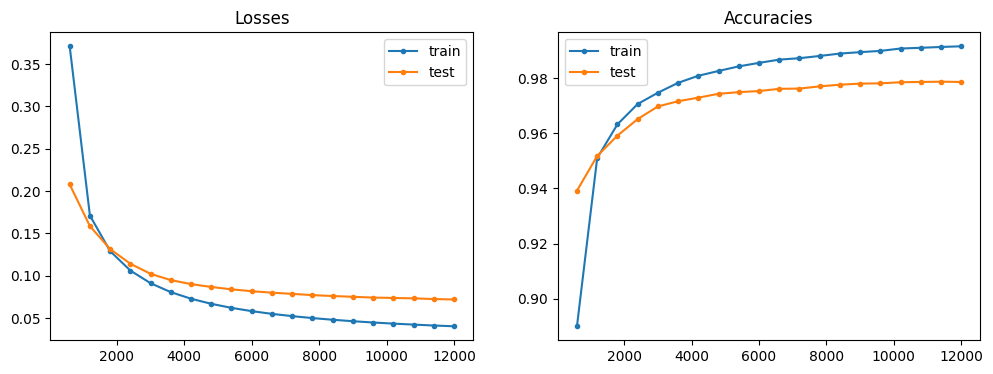

In [26]:
# 根据案例要求，还需要构造双隐含层MLP
# Note on Performance. Refer to the archived source for the detailed original comment.

max_epoch = 20            # 提升训练 epoch
learning_rate_SGD = 0.01  # 降低学习率

mlp_custom = Network()

# Note on Input. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(784, 256)) #用 He 初始化
mlp_custom.add(ReLULayer())

# 第二层：隐层 256 -> 隐层 128
mlp_custom.add(FCLayer(256, 128)) #用 He 初始化
mlp_custom.add(ReLULayer())

# Note on Classification, Output. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(128, 10))

# Note on Loss Function. Refer to the archived source for the detailed original comment.
criterion_custom = SoftmaxCrossEntropyLossLayer()

# Note on Optimizer. Refer to the archived source for the detailed original comment.
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_custom, avg_test_losses, avg_test_accs = train(mlp_custom, criterion_custom, sgd)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Experiment / Results / Classification

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Ep[0] loss:0.251 acc:0.960: 100%|████████████| 600/600 [00:00<00:00, 662.45it/s]


  - Test loss:0.1907 acc:0.9407


Ep[1] loss:0.224 acc:0.970: 100%|████████████| 600/600 [00:00<00:00, 676.54it/s]


  - Test loss:0.1549 acc:0.9484


Ep[2] loss:0.206 acc:0.980: 100%|████████████| 600/600 [00:00<00:00, 699.17it/s]


  - Test loss:0.1398 acc:0.9530


... (30 outputs left out)

Ep[18] loss:0.104 acc:0.990: 100%|███████████| 600/600 [00:00<00:00, 662.61it/s]


  - Test loss:0.0721 acc:0.9786


Ep[19] loss:0.095 acc:0.990: 100%|███████████| 600/600 [00:00<00:00, 679.47it/s]


  - Test loss:0.0725 acc:0.9787


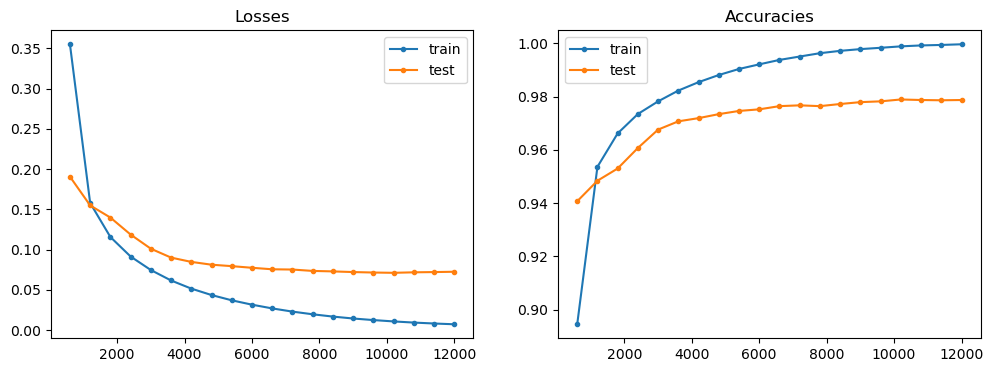

In [15]:
# 根据案例要求，还需要构造双隐含层MLP
# Note on Performance. Refer to the archived source for the detailed original comment.

max_epoch = 20            # 提升训练 epoch
learning_rate_SGD = 0.01  # 降低学习率
weight_decay = 0          # 不使用weight decay 权重衰减

mlp_custom = Network()

# Note on Input. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(784, 256)) #用 He 初始化
mlp_custom.add(ReLULayer())

# 第二层：隐层 256 -> 隐层 128
mlp_custom.add(FCLayer(256, 128)) #用 He 初始化
mlp_custom.add(ReLULayer())

# Note on Classification, Output. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(128, 10))

# Note on Loss Function. Refer to the archived source for the detailed original comment.
criterion_custom = SoftmaxCrossEntropyLossLayer()

# Note on Optimizer. Refer to the archived source for the detailed original comment.
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_custom, avg_test_losses, avg_test_accs = train(mlp_custom, criterion_custom, sgd)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Model / Training / Testing

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [13]:
class DropoutLayer():
    ''' Dropout 层（随机失活） '''
    def __init__(self, keep_prob=0.5):
        """
        keep_prob: 神经元被保留的概率（即丢弃概率为 1 - keep_prob）
        """
        self.keep_prob = keep_prob
        self.trainable = False          # 没有可训练的参数
        self.mask = None                # 保存前向传播时的掩码，用于反向传播
        self.training = True            # 默认训练模式，测试时设为 False

    def forward(self, input):
        """
        前向传播
        - 训练时：按 keep_prob 随机失活，并除以 keep_prob 保持期望一致
        - 测试时：直接输出 input（不做任何操作）
        """
        if self.training and self.keep_prob < 1.0:
            # Note on Generate. Refer to the archived source for the detailed original comment.
            self.mask = (np.random.rand(*input.shape) < self.keep_prob)
            # Note on Output, Data. Refer to the archived source for the detailed original comment.
            out = input * self.mask / self.keep_prob
            return out
        else:
            # Note on Testing. Refer to the archived source for the detailed original comment.
            return input

    def backward(self, delta):
        """
        反向传播
        - 训练时：梯度只通过被保留的神经元，并除以 keep_prob
        - 测试时：直接返回 delta（无操作）
        """
        if self.training and self.keep_prob < 1.0:
            # Note on Gradient. Refer to the archived source for the detailed original comment.
            return delta * self.mask / self.keep_prob
        else:
            return delta

In [14]:
gc.collect()

11684

### Training

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [15]:
def train_pro(model, criterion, optimizer):
    avg_train_losses, avg_train_accs = [], []
    avg_test_losses, avg_test_accs = [], []
    
    # Note on Training. Refer to the archived source for the detailed original comment.
    for layer in model.layers:
        if hasattr(layer, 'training'):
            layer.training = True

    # Train
    for epoch in range(max_epoch):
        # Note on Training. Refer to the archived source for the detailed original comment.
        perm = np.random.permutation(len(train_data))
        train_data_shuffled = train_data[perm]
        train_labels_shuffled = train_labels[perm]

        # Note on Data. Refer to the archived source for the detailed original comment.
        steps_per_epoch = int(np.ceil(len(train_data_shuffled) / batch_size))
        batch_split_indices = np.arange(batch_size, len(train_data_shuffled), batch_size)
        train_data_batches = np.split(train_data_shuffled, batch_split_indices)
        train_labels_batches = np.split(train_labels_shuffled, batch_split_indices)

        batch_train_losses, batch_train_accs = [], []

        progress_bar = tqdm.tqdm(range(steps_per_epoch), desc=f'Ep[{epoch}]')

        for step_index in progress_bar:
            # Get train data and label
            x = np.reshape(train_data_batches[step_index], (-1, 784))
            y_true = np.eye(10)[train_labels_batches[step_index]]

            # Forward pass
            y_pred = model.forward(x)
            criterion.forward(y_pred, y_true)

            # Backward pass
            delta = criterion.backward()
            model.backward(delta)

            # Update weights
            optimizer.step(model)

            # Record loss and accuracy
            batch_train_losses.append(criterion.loss)
            batch_train_accs.append(criterion.acc)

            progress_bar.set_description(
                f'Ep[{epoch}] loss:{criterion.loss:.3f} acc:{criterion.acc:.3f}'
            )
            

        # Note on Testing. Refer to the archived source for the detailed original comment.
        for layer in model.layers:
            if hasattr(layer, 'training'):
                layer.training = False

        # test（ Dropout 层直接通过，不丢弃神经元）
        x = np.reshape(test_data, (-1, 784))
        y_true = np.eye(10)[test_labels]

        y_pred = model.forward(x)
        criterion.forward(y_pred, y_true)

        test_loss = criterion.loss
        test_acc = criterion.acc

        # Note on Training, Testing. Refer to the archived source for the detailed original comment.
        for layer in model.layers:
            if hasattr(layer, 'training'):
                layer.training = True
                
        avg_train_losses.append(np.mean(batch_train_losses))
        avg_train_accs.append(np.mean(batch_train_accs))
        avg_test_losses.append(test_loss)
        avg_test_accs.append(test_acc)

        print(f'  - Test loss:{avg_test_losses[-1]:.4f} acc:{avg_test_accs[-1]:.4f}')

    # plot loss & accuracy curve
    x_by_epoch = (np.arange(max_epoch) + 1) * steps_per_epoch

    fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 4))

    a0.set_title('Losses')
    a0.plot(x_by_epoch, avg_train_losses, marker='.', label='train')
    a0.plot(x_by_epoch, avg_test_losses, marker='.', label='test')
    a0.legend()

    a1.set_title('Accuracies')
    a1.plot(x_by_epoch, avg_train_accs, marker='.', label='train')
    a1.plot(x_by_epoch, avg_test_accs, marker='.', label='test')
    a1.legend()

    plt.show()

    return model, avg_test_losses, avg_test_accs

Ep[0] loss:0.369 acc:0.890: 100%|██████████| 600/600 [00:08<00:00, 74.43it/s]


  - Test loss:0.2689 acc:0.9214


Ep[1] loss:0.341 acc:0.860: 100%|██████████| 600/600 [00:07<00:00, 75.47it/s]


  - Test loss:0.2041 acc:0.9385


Ep[2] loss:0.302 acc:0.900: 100%|██████████| 600/600 [00:07<00:00, 76.62it/s]


  - Test loss:0.1673 acc:0.9500


... (50 outputs left out)

Ep[28] loss:0.100 acc:0.970: 100%|██████████| 600/600 [00:07<00:00, 75.23it/s]


  - Test loss:0.0652 acc:0.9806


Ep[29] loss:0.064 acc:0.990: 100%|██████████| 600/600 [00:07<00:00, 76.99it/s]


  - Test loss:0.0681 acc:0.9802


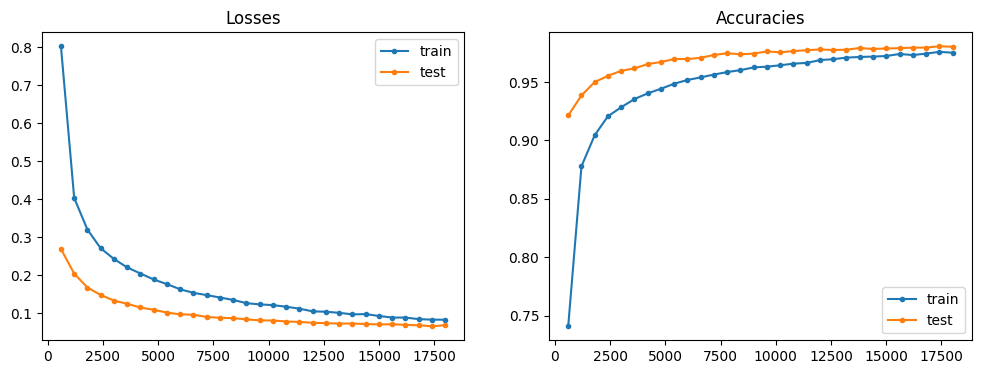

In [17]:
np.random.seed(42)

batch_size = 100
max_epoch = 30             #增加训练轮次，减小学习率
learning_rate_SGD = 0.005
weight_decay = 1e-4
EPS = 1e-11

mlp_custom = Network()
mlp_custom.add(FCLayer(784, 512))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.5))   # 随机失活层

mlp_custom.add(FCLayer(512, 128))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.5))   # 随机失活层

#Note on Output. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(128, 10))

criterion_custom = SoftmaxCrossEntropyLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_custom, avg_test_losses, avg_test_accs = train_pro(
    mlp_custom,
    criterion_custom,
    sgd
)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


Ep[0] loss:0.288 acc:0.880: 100%|██████████| 600/600 [00:08<00:00, 73.93it/s]


  - Test loss:0.2330 acc:0.9312


Ep[1] loss:0.292 acc:0.900: 100%|██████████| 600/600 [00:08<00:00, 70.71it/s]


  - Test loss:0.1742 acc:0.9482


Ep[2] loss:0.192 acc:0.940: 100%|██████████| 600/600 [00:08<00:00, 72.92it/s]


  - Test loss:0.1419 acc:0.9567


... (50 outputs left out)

Ep[28] loss:0.081 acc:0.960: 100%|██████████| 600/600 [00:08<00:00, 73.08it/s]


  - Test loss:0.0584 acc:0.9822


Ep[29] loss:0.053 acc:0.980: 100%|██████████| 600/600 [00:08<00:00, 72.73it/s]


  - Test loss:0.0585 acc:0.9821


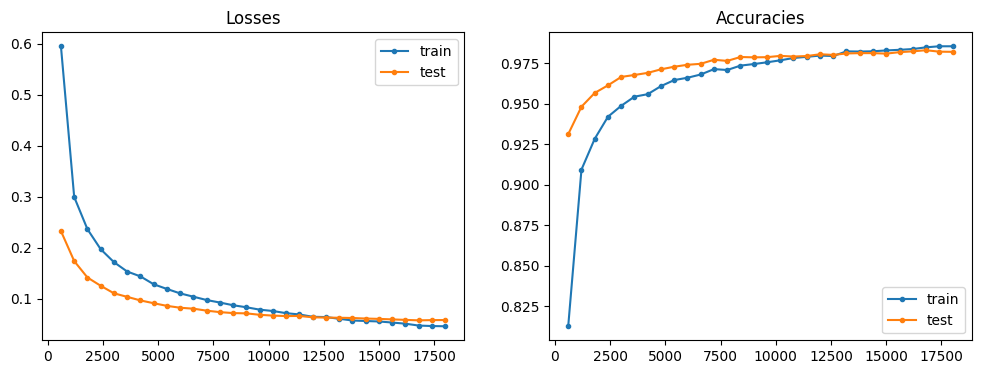

In [20]:
np.random.seed(42)

batch_size = 100
max_epoch = 30             #增加训练轮次，减小学习率
learning_rate_SGD = 0.005
weight_decay = 1e-4
EPS = 1e-11

mlp_custom = Network()
mlp_custom.add(FCLayer(784, 512))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.7))   # 随机失活层

mlp_custom.add(FCLayer(512, 128))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.7))   # 随机失活层

#Note on Output. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(128, 10))

criterion_custom = SoftmaxCrossEntropyLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_custom, avg_test_losses, avg_test_accs = train_pro(
    mlp_custom,
    criterion_custom,
    sgd
)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Model / Training / Accuracy

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [16]:
def train_pro_lr(model, criterion, optimizer, max_epoch=25, batch_size=100,
                 lr_decay_epochs=None, lr_decay_factor=0.1):
    if lr_decay_epochs is None:
        lr_decay_epochs = []

    avg_train_losses, avg_train_accs = [], []
    avg_test_losses, avg_test_accs = [], []
    
    # Note on Training. Refer to the archived source for the detailed original comment.
    for layer in model.layers:
        if hasattr(layer, 'training'):
            layer.training = True
    
    # Train
    for epoch in range(max_epoch):
        # Note on Training. Refer to the archived source for the detailed original comment.
        perm = np.random.permutation(len(train_data))
        train_data_shuffled = train_data[perm]
        train_labels_shuffled = train_labels[perm]

        steps_per_epoch = int(np.ceil(len(train_data_shuffled) / batch_size))
        batch_split_indices = np.arange(batch_size, len(train_data_shuffled), batch_size)
        train_data_batches = np.split(train_data_shuffled, batch_split_indices)
        train_labels_batches = np.split(train_labels_shuffled, batch_split_indices)

        batch_train_losses, batch_train_accs = [], []

        progress_bar = tqdm.tqdm(range(steps_per_epoch), desc=f'Ep[{epoch}]')

        for step_index in progress_bar:
            x = np.reshape(train_data_batches[step_index], (-1, 784))
            y_true = np.eye(10)[train_labels_batches[step_index]]

            y_pred = model.forward(x)
            criterion.forward(y_pred, y_true)

            delta = criterion.backward()
            model.backward(delta)

            optimizer.step(model)

            batch_train_losses.append(criterion.loss)
            batch_train_accs.append(criterion.acc)

            progress_bar.set_description(
                f'Ep[{epoch}] lr:{optimizer.learning_rate:.5f} '
                f'loss:{criterion.loss:.3f} acc:{criterion.acc:.3f}'
            )

        # Note on Testing. Refer to the archived source for the detailed original comment.
        for layer in model.layers:
            if hasattr(layer, 'training'):
                layer.training = False
                
        # Test
        x = np.reshape(test_data, (-1, 784))
        y_true = np.eye(10)[test_labels]

        y_pred = model.forward(x)
        criterion.forward(y_pred, y_true)

        test_loss = criterion.loss
        test_acc = criterion.acc
        
        # Note on Training, Testing. Refer to the archived source for the detailed original comment.
        for layer in model.layers:
            if hasattr(layer, 'training'):
                layer.training = True

        avg_train_losses.append(np.mean(batch_train_losses))
        avg_train_accs.append(np.mean(batch_train_accs))
        avg_test_losses.append(test_loss)
        avg_test_accs.append(test_acc)

        print(
            f'  - Test loss:{avg_test_losses[-1]:.4f} '
            f'acc:{avg_test_accs[-1]:.4f} '
            f'lr:{optimizer.learning_rate:.5f}'
        )

        # learning rate decay：用 epoch + 1，因为 epoch 从 0 开始
        if (epoch + 1) in lr_decay_epochs:
            optimizer.learning_rate *= lr_decay_factor
            print(f'  - Learning rate decayed to {optimizer.learning_rate:.6f}')

    x_by_epoch = (np.arange(max_epoch) + 1) * steps_per_epoch

    fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 4))

    a0.set_title('Losses')
    a0.plot(x_by_epoch, avg_train_losses, marker='.', label='train')
    a0.plot(x_by_epoch, avg_test_losses, marker='.', label='test')
    a0.legend()

    a1.set_title('Accuracies')
    a1.plot(x_by_epoch, avg_train_accs, marker='.', label='train')
    a1.plot(x_by_epoch, avg_test_accs, marker='.', label='test')
    a1.legend()

    plt.show()

    return model, avg_test_losses, avg_test_accs

Ep[0] lr:0.00500 loss:0.288 acc:0.880: 100%|██████████| 600/600 [00:07<00:00, 78.94it/s]


  - Test loss:0.2330 acc:0.9312 lr:0.00500


Ep[1] lr:0.00500 loss:0.292 acc:0.900: 100%|██████████| 600/600 [00:07<00:00, 79.26it/s]


  - Test loss:0.1742 acc:0.9482 lr:0.00500


Ep[2] lr:0.00500 loss:0.192 acc:0.940: 100%|██████████| 600/600 [00:07<00:00, 79.24it/s]


  - Test loss:0.1419 acc:0.9567 lr:0.00500


... (70 outputs left out)

Ep[38] lr:0.00125 loss:0.030 acc:1.000: 100%|██████████| 600/600 [00:07<00:00, 78.70it/s]


  - Test loss:0.0558 acc:0.9829 lr:0.00125


Ep[39] lr:0.00125 loss:0.036 acc:0.990: 100%|██████████| 600/600 [00:07<00:00, 75.87it/s]


  - Test loss:0.0557 acc:0.9833 lr:0.00125


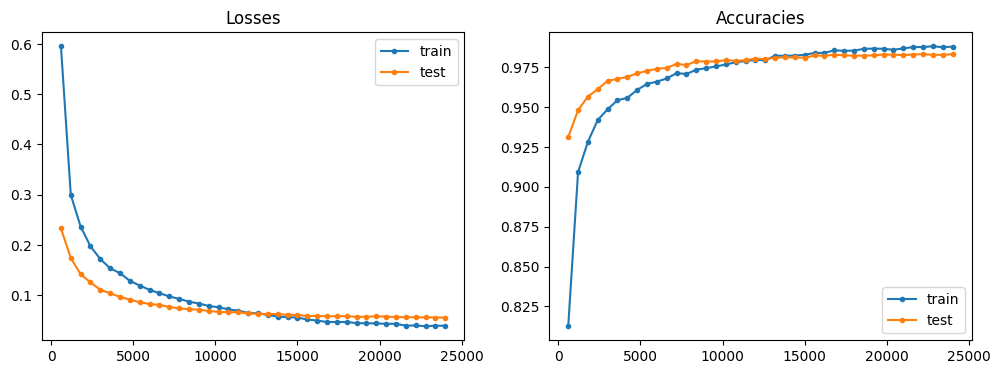

In [17]:
np.random.seed(42)

max_epoch = 40
batch_size = 100

learning_rate_SGD = 0.005
weight_decay = 1e-4
EPS = 1e-11

# 只在第 25、35 个 epoch 结束后衰减为 0.5 倍
lr_decay_epochs = [25, 35]
lr_decay_factor = 0.5

mlp_custom = Network()
mlp_custom.add(FCLayer(784, 512))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.7))   # 随机失活层

mlp_custom.add(FCLayer(512, 128))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.7))   # 随机失活层

#Note on Output. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(128, 10))

criterion_custom = SoftmaxCrossEntropyLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_custom, test_losses, test_accs = train_pro_lr(
    mlp_custom, criterion_custom, sgd,
    max_epoch=max_epoch,
    batch_size=batch_size,
    lr_decay_epochs=lr_decay_epochs,
    lr_decay_factor=lr_decay_factor
)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [20]:
gc.collect()

7611

Ep[0] lr:0.00500 loss:0.288 acc:0.880: 100%|██████████| 600/600 [00:08<00:00, 74.57it/s]


  - Test loss:0.2330 acc:0.9312 lr:0.00500


Ep[1] lr:0.00500 loss:0.292 acc:0.900: 100%|██████████| 600/600 [00:08<00:00, 72.99it/s]


  - Test loss:0.1742 acc:0.9482 lr:0.00500


Ep[2] lr:0.00500 loss:0.192 acc:0.940: 100%|██████████| 600/600 [00:07<00:00, 76.36it/s]


  - Test loss:0.1419 acc:0.9567 lr:0.00500


... (90 outputs left out)

Ep[48] lr:0.00063 loss:0.018 acc:1.000: 100%|██████████| 600/600 [00:07<00:00, 77.00it/s]


  - Test loss:0.0560 acc:0.9834 lr:0.00063


Ep[49] lr:0.00063 loss:0.034 acc:0.980: 100%|██████████| 600/600 [00:07<00:00, 75.77it/s]


  - Test loss:0.0555 acc:0.9832 lr:0.00063


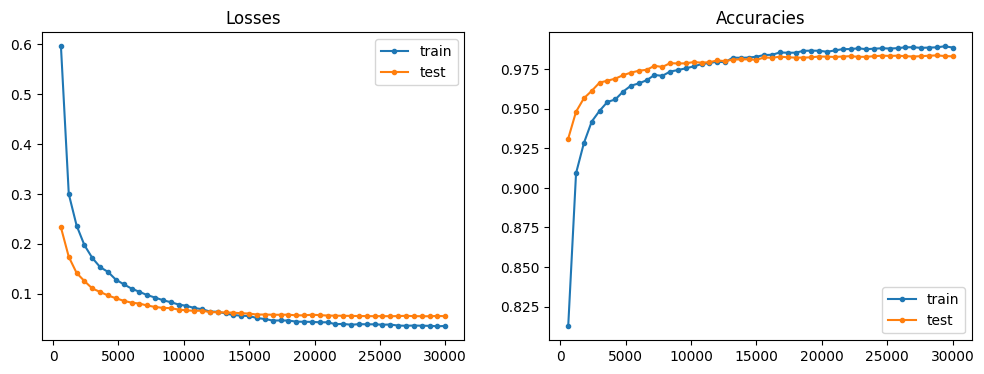

In [19]:
np.random.seed(42)

max_epoch = 50
batch_size = 100

learning_rate_SGD = 0.005
weight_decay = 1e-4
EPS = 1e-11

# 关键改动：在 25、35、45 轮后各衰减一次（每次乘以 0.5）
# Note on Samples. Refer to the archived source for the detailed original comment.
lr_decay_epochs = [25, 35, 45]
lr_decay_factor = 0.5

mlp_custom = Network()
mlp_custom.add(FCLayer(784, 512))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.7))   # 随机失活层

mlp_custom.add(FCLayer(512, 128))
mlp_custom.add(ReLULayer())
mlp_custom.add(DropoutLayer(keep_prob=0.7))   # 随机失活层

#Note on Output. Refer to the archived source for the detailed original comment.
mlp_custom.add(FCLayer(128, 10))

criterion_custom = SoftmaxCrossEntropyLossLayer()
sgd = SGD(learning_rate_SGD, weight_decay)

mlp_custom, test_losses, test_accs = train_pro_lr(
    mlp_custom, criterion_custom, sgd,
    max_epoch=max_epoch,
    batch_size=batch_size,
    lr_decay_epochs=lr_decay_epochs,
    lr_decay_factor=lr_decay_factor
)

### Results and Analysis / Results / Analysis

This cell documents the building a multilayer perceptron experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.
